# Calibrated fluorescence lifetime imaging


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`measurements`，shape `(1, 256, 256, 256)`，dtype `<u2`：Native spatial image photon counts; axes batch,y,x,delay; unit photons per delay bin accumulated over 40 frames；`calibration`，shape `(1, 1, 1, 256)`，dtype `<u8`：Independently measured fluorescein photon histogram pooled over its entire spatial image; unit photons per delay bin；`valid_mask`，shape `(1, 256, 256)`，dtype `|u1`：Fixed observation-validity support, 1 valid and 0 excluded; dimensionless。未知量为256×256相位与调制表观荧光寿命图，ns。

获取模型：仪器响应与周期指数荧光衰减卷积产生时延计数直方图。

如何恢复：src.solvers.reconstruct；normalized_phasor/calibrate/lifetimes闭式一阶谐波。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell7寿命/参考比较；8原生计数、独立荧光素校准及phasor；9空间寿命和异质性解释。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留3个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。4.1ns校准染料是独立仪器参考，不能当组织寿命GT。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Reconstruct phase and modulation fluorescence lifetime maps from real photon arrival histograms despite instrument timing distortion and mixed fluorophore decays.

This notebook actively reconstructs the bundled observations. The reproduced upstream result is a method reference, not physical ground truth. No historical paper metric is presented as a measurement from this run.


## 2. Data

| Key | Shape | Dtype | Description |
| --- | --- | --- | --- |
| measurements | (1, 256, 256, 256) | uint16 | Native spatial image photon counts; axes batch,y,x,delay; unit photons per delay bin accumulated over 40 frames |
| calibration | (1, 1, 1, 256) | uint64 | Independently measured fluorescein photon histogram pooled over its entire spatial image; unit photons per delay bin |
| valid_mask | (1, 256, 256) | uint8 | Fixed observation-validity support, 1 valid and 0 excluded; dimensionless |

**Acquisition metadata**

| Parameter | Value | Unit | Meaning |
| --- | --- | --- | --- |
| Laser period | 24.99989318828099 | ns | Stored acquisition value; periodic temporal boundary |
| Fundamental frequency | 40.00017089948058 | MHz | Reciprocal period in matching units |
| Time bins | 256 | dimensionless | Uniform bins k=0,...,255 with t=k period/256 |
| Calibration lifetime | 4.1 | ns | Independently known fluorescein lifetime |
| Frames | 40 | dimensionless | Sample accumulation frames |
| Spatial grid | 256 by 256 | pixels | Original complete field of view, no resampling |
| Spatial coordinates | y then x, zero based | pixels | Original stored detector indexing; physical pixel pitch is unavailable and not needed for independent per-pixel inversion |
| Noise | Photon counting | photons | No background or Gaussian variance correction is supplied |
| Validity convention | count sum at least 200; G>0; S>0; G²+S²<1 | dimensionless | Fixed support derived solely from observations and independent calibration, before scoring |

Calibration photons are summed before normalization, equivalently giving intensity-weighted calibration phasor averaging. No dark count, time shift, median filter or implicit histogram offset is prescribed.


Real full-field Convallaria photon histograms are calibrated against an independent 4.1 ns fluorescein measurement. The complete native 256 by 256 grid is reconstructed.


## 3. Physics

The observations are a native-resolution Convallaria microscopy image and a separate fluorescein calibration measurement. At each spatial pixel, the expected periodic histogram is proportional to the circular convolution of the instrument response with the fluorescence decay, sampled over one laser period. For delay index k, denote measured counts by h(k), the number of time bins by N, and normalized first-harmonic coordinates by g and s:


$$
g=\frac{\sum_{k=0}^{N-1}h(k)\cos(2\pi k/N)}{\sum_k h(k)},\qquad
s=\frac{\sum_{k=0}^{N-1}h(k)\sin(2\pi k/N)}{\sum_k h(k)}.
$$


Let the calibration phasor be zc and the sample phasor z=g+is, where i is the imaginary unit. The ideal calibration phasor for known lifetime tc at angular frequency w is zt=1/(1-i w tc). The corrected sample phasor is Z=z zt/zc=G+iS. The two apparent lifetimes are defined as


$$
\tau_{\phi}=\frac{S}{\omega G},\qquad
\tau_{m}=\frac{\sqrt{(G^2+S^2)^{-1}-1}}{\omega},\qquad
\omega=2\pi f\,10^{-3}.
$$


Here f is in MHz, w is in inverse ns, and all lifetimes are in ns. A multiexponential decay generally has different phase and modulation apparent lifetimes; neither is claimed to be a unique component lifetime. Recover both physical summary maps. Photon fluctuations and the unknown instrumental response prevent a direct interpretation of raw histogram shape as lifetime.


## 4. Method

### Physics and method

At each pixel the normalized cosine/sine harmonic of the photon histogram is z=g+is. Independent standard calibration gives Z=z times zt/zc=G+iS, where zt=1/(1-i omega tc), tc=4.1 ns, and omega=2 pi f times 0.001 in inverse ns. Phase lifetime is S/(omega G), and modulation lifetime is sqrt(1/(G squared+S squared)-1)/omega. Count support and physical-domain validity are fixed from observations; excluded pixels are zero.


For counts $h_k$ at harmonic angles $\theta_k=2\pi k/256$, compute

$$
z=\frac{\sum_k h_k e^{i\theta_k}}{\sum_k h_k},\qquad
Z=z\frac{z_t}{z_c}=G+iS,\qquad z_t=\frac{1}{1-i\omega t_c}.
$$

Here $z_c$ is the photon-pooled independent fluorescein phasor, $t_c=4.1$ ns and $\omega$ is the calibrated excitation angular frequency in inverse ns. The direct inverse is

$$
\tau_\phi=\frac{S}{\omega G},\qquad
\tau_m=\frac{\sqrt{1/(G^2+S^2)-1}}{\omega}.
$$

Both outputs are in ns. Fixed count support and physical-domain checks exclude undefined apparent lifetimes; there is no iterative optimizer, decay-component fitting or learned prior.


## 5. Results

The preserved code below contains the active reconstruction and comparison path. Its saved outputs are retained from the earlier execution. This documentation edit does not rerun that path; displayed measurements remain evidence of the stored execution rather than a new numerical run.


In [1]:
from pathlib import Path
import sys,time,json,numpy as np
from matplotlib import pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'src').exists(): ROOT=ROOT.parent
if not (ROOT/'src').exists(): raise RuntimeError('Execute from task or notebooks directory')
sys.path.insert(0,str(ROOT))
from src.solvers import reconstruct
from src.visualization import comparison,metrics
started=time.perf_counter()
fresh=reconstruct(ROOT/'data/raw_data.npz')
runtime=time.perf_counter()-started
reference=dict(np.load(ROOT/'notebooks/reference_outputs/upstream.npz',allow_pickle=False))
print('Fresh local reconstruction CPU wall seconds:',runtime)
for key,value in fresh.items(): print(key,value.shape,value.dtype,metrics(value,reference[key]))
print('Kernel:',sys.executable,'NumPy:',np.__version__)

Fresh local reconstruction CPU wall seconds: 0.11575670004822314
reconstruction (1, 256, 256) float64 (1.0, 1.5900336528811471e-16)
modulation_lifetime (1, 256, 256) float64 (1.0000000000000002, 4.079432901393218e-16)
Kernel: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe NumPy: 2.4.6


In [2]:
import hashlib
ledger=json.loads((ROOT/'notebooks/reference_outputs/fresh_metrics.json').read_text(encoding='utf-8'))
assert ledger['observation_sha256']==hashlib.sha256((ROOT/'data/raw_data.npz').read_bytes()).hexdigest()
print('Measurement ledger:',ledger['kind'])
for key in fresh:
 n,e=metrics(fresh[key],reference[key])
 assert abs(e-ledger['judge_report']['metrics'][key+'_nrmse'])<1e-12
print('Fresh measurement ledger matches this active reconstruction.')

Measurement ledger: fresh cleaned-code measurement, not historical report
Fresh measurement ledger matches this active reconstruction.


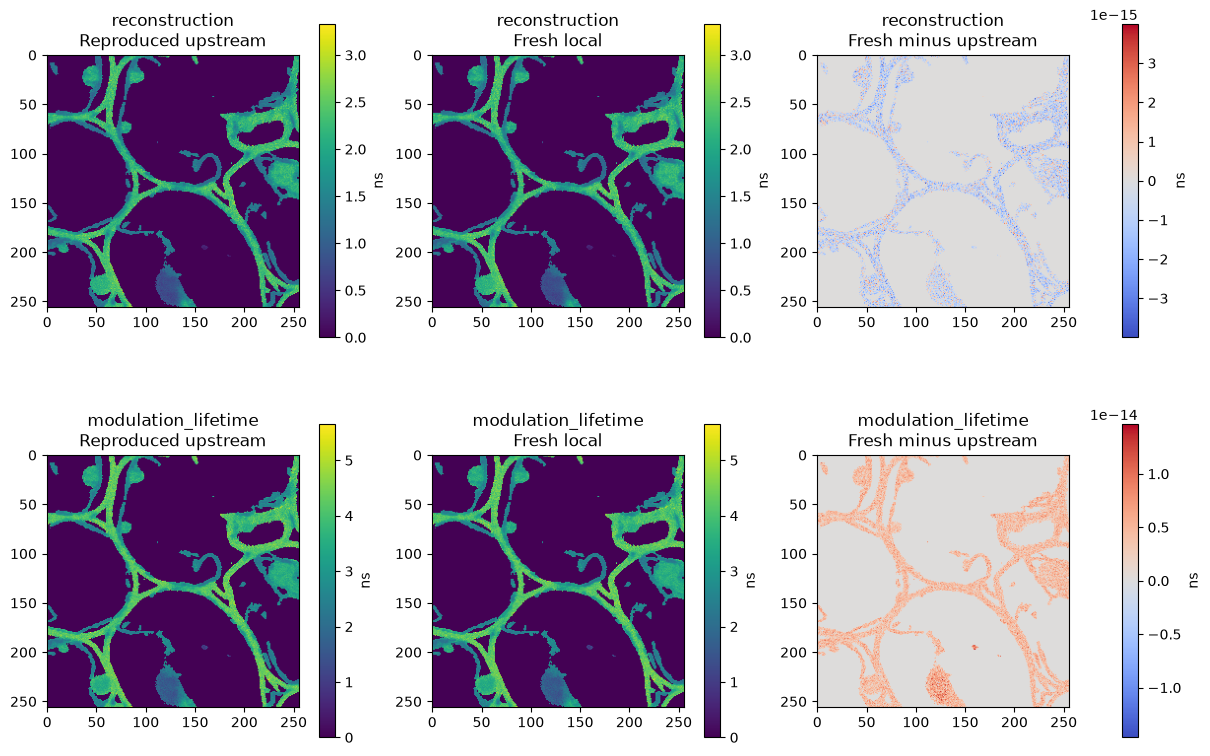

In [3]:
fig=comparison(fresh,reference)
plt.show()

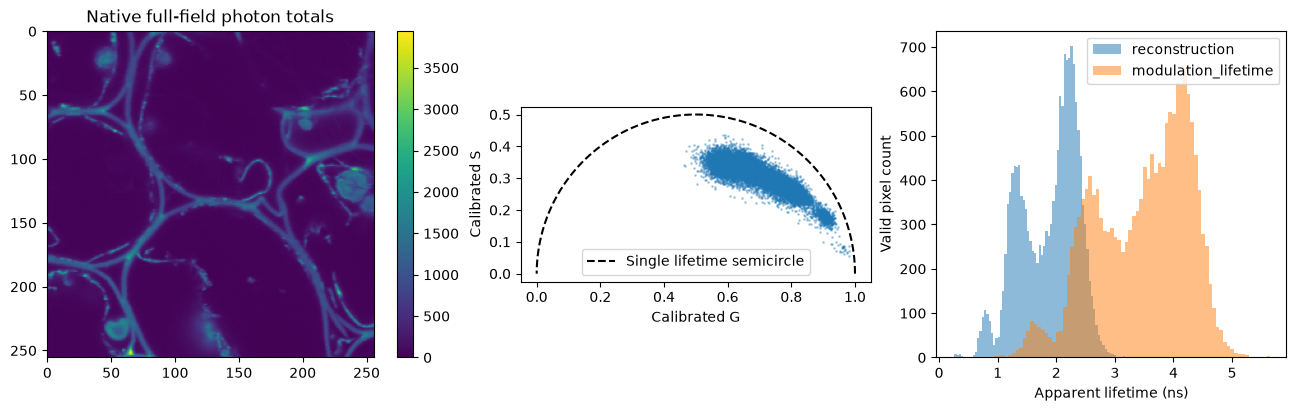

In [4]:
from src.preprocessing import load_data
from src.physics_model import normalized_phasor,calibrate
counts,dye,mask=load_data(ROOT/'data/raw_data.npz')
_,g,s=normalized_phasor(counts);G,S=calibrate(g,s,dye)
fig,axes=plt.subplots(1,3,figsize=(13,4),layout='constrained')
im=axes[0].imshow(counts.sum(-1));fig.colorbar(im,ax=axes[0]);axes[0].set_title('Native full-field photon totals')
theta=np.linspace(0,np.pi,200)
axes[1].scatter(G[mask],S[mask],s=1,alpha=.3)
axes[1].plot(.5+.5*np.cos(theta),.5*np.sin(theta),'k--',label='Single lifetime semicircle')
axes[1].set(xlabel='Calibrated G',ylabel='Calibrated S',aspect='equal');axes[1].legend()
for k in fresh:axes[2].hist(fresh[k][0][mask],bins=80,alpha=.5,label=k)
axes[2].set(xlabel='Apparent lifetime (ns)',ylabel='Valid pixel count');axes[2].legend()
plt.show()


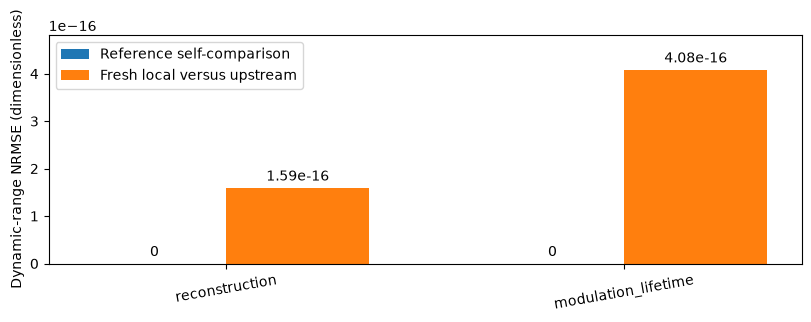

{
  "reconstruction": {
    "NCC": 1.0,
    "dynamic_range_NRMSE": 1.5900336528811471e-16
  },
  "modulation_lifetime": {
    "NCC": 1.0000000000000002,
    "dynamic_range_NRMSE": 4.079432901393218e-16
  }
}


In [5]:
labels=list(fresh)
errors=[metrics(fresh[k],reference[k])[1] for k in labels]
fig,ax=plt.subplots(figsize=(8,3),layout='constrained')
x=np.arange(len(labels))
reference_bars=ax.bar(x-.18,[metrics(reference[k],reference[k])[1] for k in labels],.36,label='Reference self-comparison')
fresh_bars=ax.bar(x+.18,errors,.36,label='Fresh local versus upstream')
ax.margins(y=.18)
ax.bar_label(reference_bars,fmt='%.3g',padding=3)
ax.bar_label(fresh_bars,fmt='%.3g',padding=3)
ax.set_xticks(x,labels,rotation=10);ax.set_ylabel('Dynamic-range NRMSE (dimensionless)');ax.legend()
if all(error==0 for error in errors):
 ax.set_ylim(0,1e-6)
 ax.text(.5,.7,'Fresh and upstream arrays are bitwise equal; both plotted errors are 0.',ha='center',va='center',transform=ax.transAxes,wrap=True)
plt.show()
print(json.dumps({k:dict(zip(['NCC','dynamic_range_NRMSE'],metrics(fresh[k],reference[k]))) for k in labels},indent=2))

### Interpretation

The phase and modulation lifetimes differ in this heterogeneous tissue; their distinction is retained rather than interpreting every pixel as one exponential component. Numerical reference agreement establishes extraction fidelity; it does not establish biological or clinical accuracy.


## 6. Conclusion

Phase and modulation lifetimes are different apparent quantities for a heterogeneous decay. Independent fluorescein calibration removes a harmonic instrument response, while count support excludes undefined pixels. Their disagreement does not identify a unique mixture of molecular lifetimes.
